<a href="https://colab.research.google.com/github/arxsyy/PCVK_Ganjil_2026/blob/main/Week10_1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# Import library yang dibutuhkan
import cv2 as cv
import numpy as np
from matplotlib import pyplot as plt

# Akses Google Drive
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


2. Implementasi 6 Metode Template Matching

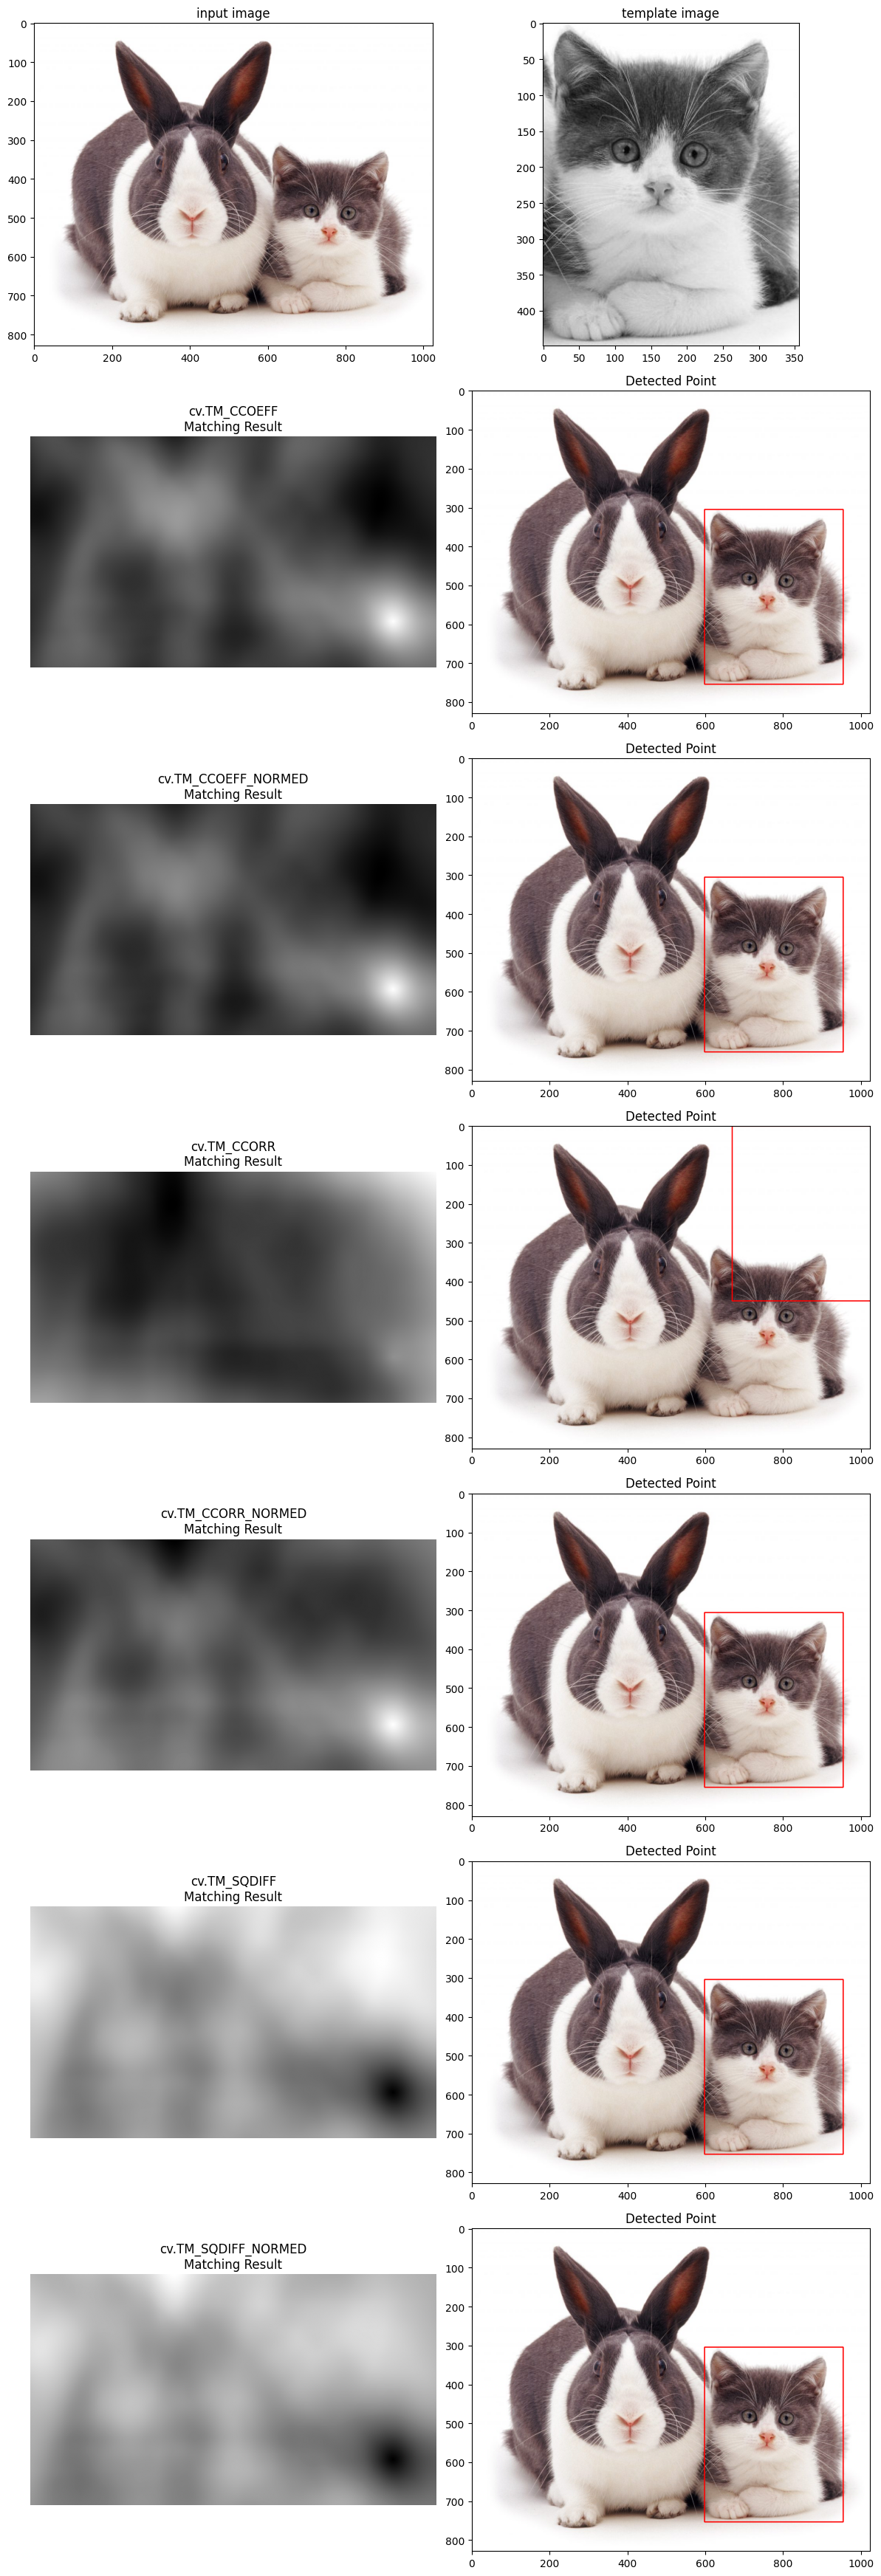

In [ ]:

# Membaca gambar
img = cv.imread('/content/drive/MyDrive/PCVK/Images/Object Detection/Object Detection/cats_and_bunnies.jpg')
template = cv.imread('/content/drive/MyDrive/PCVK/Images/Object Detection/Object Detection/cat2_template.jpg')

img_gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)
template_gray = cv.cvtColor(template, cv.COLOR_BGR2GRAY)

img_rgb = cv.cvtColor(img, cv.COLOR_BGR2RGB)

h, w = template_gray.shape

# 6 metode Template Matching
methods = [
    cv.TM_CCOEFF,
    cv.TM_CCOEFF_NORMED,
    cv.TM_CCORR,
    cv.TM_CCORR_NORMED,
    cv.TM_SQDIFF,
    cv.TM_SQDIFF_NORMED
]

# Membuat tampilan hasil
fig, axes = plt.subplots(7, 2, figsize=(12, 35))

# Menampilkan gambar input dan template
axes[0, 0].imshow(img_rgb)
axes[0, 0].set_title('input image')
axes[0, 0].axis('on')

axes[0, 1].imshow(template_gray, cmap='gray')
axes[0, 1].set_title('template image')
axes[0, 1].axis('on')


# Proses setiap metode
for i, method in enumerate(methods):

    result = cv.matchTemplate(img_gray, template_gray, method)

    min_val, max_val, min_loc, max_loc = cv.minMaxLoc(result)

    result_norm = cv.normalize(
        result, None, 0, 255, cv.NORM_MINMAX
    ).astype(np.uint8)

    if method in [cv.TM_SQDIFF, cv.TM_SQDIFF_NORMED]:
        top_left = min_loc
    else:
        top_left = max_loc

    bottom_right = (top_left[0] + w, top_left[1] + h)

    # Matching Result
    axes[i+1, 0].imshow(result_norm, cmap='gray')
    axes[i+1, 0].set_title('cv.' + [
        'TM_CCOEFF',
        'TM_CCOEFF_NORMED',
        'TM_CCORR',
        'TM_CCORR_NORMED',
        'TM_SQDIFF',
        'TM_SQDIFF_NORMED'
    ][i] + '\nMatching Result')
    axes[i+1, 0].axis('off')

    # Detected Point
    detected = img_rgb.copy()

    cv.rectangle(detected, top_left, bottom_right, (255, 0, 0), 2)

    axes[i+1, 1].imshow(detected)
    axes[i+1, 1].set_title('Detected Point')
    axes[i+1, 1].axis('on')

plt.tight_layout()
plt.show()

3. Template Matching Tanpa OpenCV (Multiple Object)

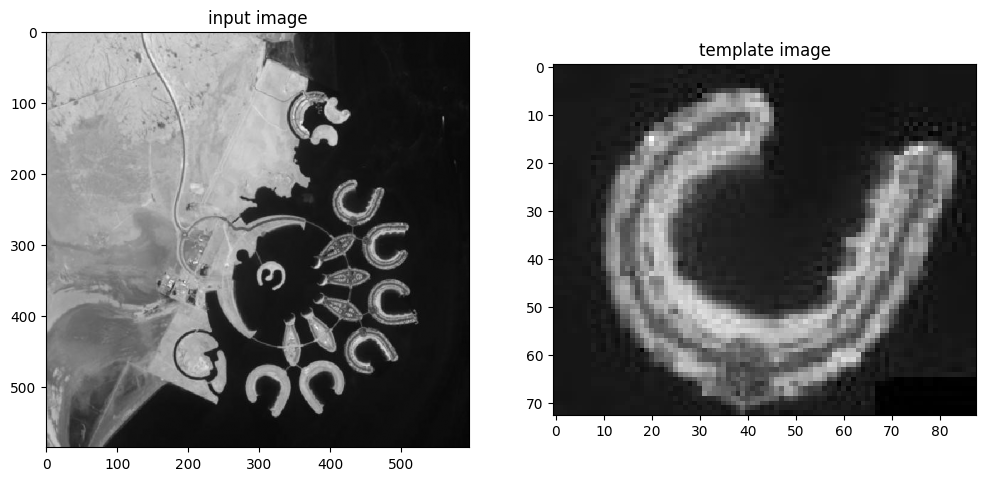

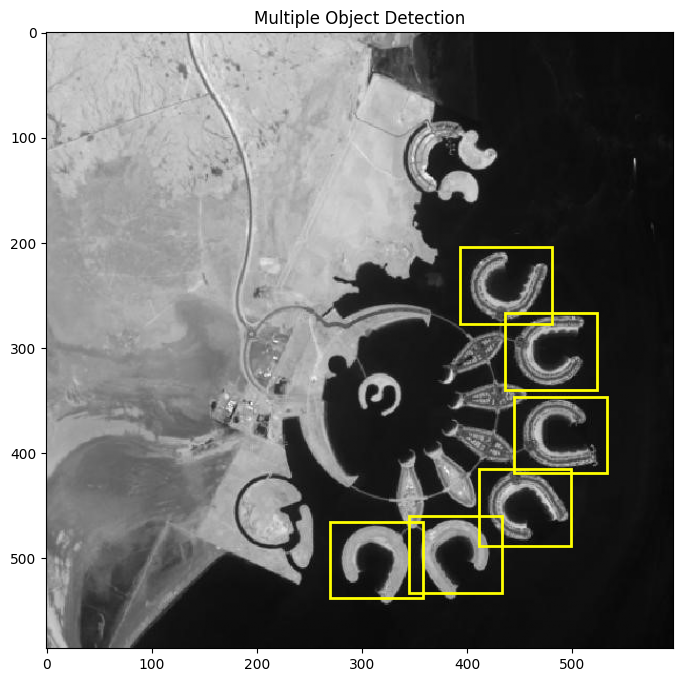

Jumlah objek terdeteksi: 6


In [34]:
## 3. Template Matching Multiple Object Tanpa OpenCV

from PIL import Image
from scipy.signal import correlate2d
from scipy.ndimage import maximum_filter
import numpy as np
import matplotlib.pyplot as plt

# Membaca gambar
img = np.array(Image.open('/content/drive/MyDrive/PCVK/Images/Object Detection/bahrain.jpg').convert('L'))
template = np.array(Image.open('/content/drive/MyDrive/PCVK/Images/Object Detection/bahrain-template.jpg').convert('L'))

img = img.astype(float)
template = template.astype(float)

h, w = template.shape

# Menghitung korelasi template
template_mean = template - np.mean(template)
template_norm = np.sum(template_mean ** 2)

result = correlate2d(img, template_mean, mode='valid')

# Menghitung normalisasi citra
integral = np.pad(img, ((1, 0), (1, 0))).cumsum(0).cumsum(1)
integral_sq = np.pad(img ** 2, ((1, 0), (1, 0))).cumsum(0).cumsum(1)

sum_img = integral[h:, w:] - integral[:-h, w:] - integral[h:, :-w] + integral[:-h, :-w]
sum_sq = integral_sq[h:, w:] - integral_sq[:-h, w:] - integral_sq[h:, :-w] + integral_sq[:-h, :-w]

variance = sum_sq - (sum_img ** 2) / (h * w)

# Normalized Cross Correlation
denominator = np.sqrt(np.maximum(variance, 0) * template_norm)
result = result / np.maximum(denominator, 1e-10)

# Menentukan threshold
threshold = 0.45

# Mencari titik kecocokan tertinggi
local_max = maximum_filter(result, size=(h, w))

peaks = (result >= threshold) & (result >= local_max - 1e-10)

y, x = np.where(peaks)

# Non-Maximum Suppression
scores = result[y, x]
order = np.argsort(scores)[::-1]

detections = []

for i in order:
    box = (x[i], y[i], x[i] + w, y[i] + h)

    overlap = False

    for prev in detections:
        xx1 = max(box[0], prev[0])
        yy1 = max(box[1], prev[1])
        xx2 = min(box[2], prev[2])
        yy2 = min(box[3], prev[3])

        inter = max(0, xx2 - xx1) * max(0, yy2 - yy1)

        area1 = w * h
        area2 = (prev[2] - prev[0]) * (prev[3] - prev[1])

        iou = inter / (area1 + area2 - inter)

        if iou > 0.3:
            overlap = True
            break

    if not overlap:
        detections.append(box)

# Menampilkan input image dan template image
plt.figure(figsize=(12, 6))

plt.subplot(1, 2, 1)
plt.imshow(img, cmap='gray')
plt.title('input image')

plt.subplot(1, 2, 2)
plt.imshow(template, cmap='gray')
plt.title('template image')

plt.show()

# Menampilkan hasil multiple object detection
plt.figure(figsize=(10, 8))
plt.imshow(img, cmap='gray')

for (x1, y1, x2, y2) in detections:
    plt.gca().add_patch(
        plt.Rectangle(
            (x1, y1), w, h,
            fill=False,
            edgecolor='yellow',
            linewidth=2
        )
    )

plt.title('Multiple Object Detection')
plt.show()

print('Jumlah objek terdeteksi:', len(detections))


4. Implementasi Edge Detection

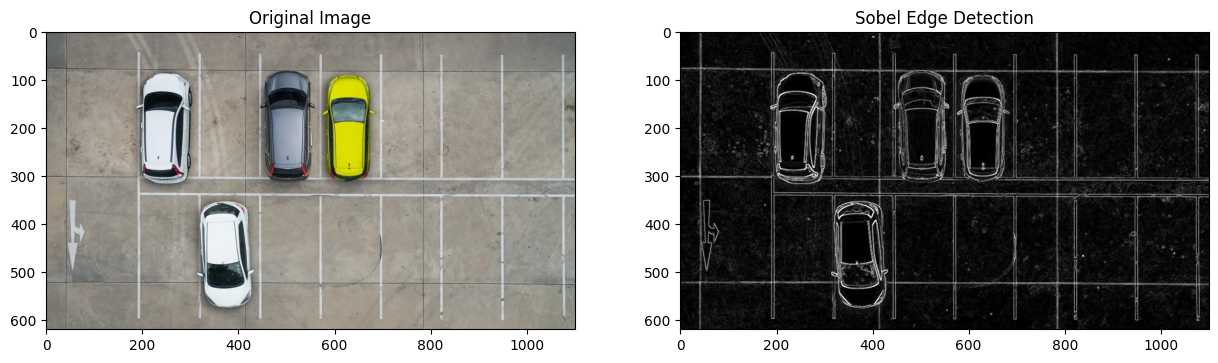

In [37]:
## 4a. Sobel Edge Detection

img = cv.imread('/content/drive/MyDrive/PCVK/Images/Object Detection/car-park.jpg')
gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)

# Sobel Edge Detection
sobelx = cv.Sobel(gray, cv.CV_64F, 1, 0, ksize=3)
sobely = cv.Sobel(gray, cv.CV_64F, 0, 1, ksize=3)

# Konversi hasil Sobel
abs_sobelx = cv.convertScaleAbs(sobelx)
abs_sobely = cv.convertScaleAbs(sobely)

# Menggabungkan hasil Sobel X dan Y
sobel = cv.addWeighted(abs_sobelx, 0.5, abs_sobely, 0.5, 0)

# Menampilkan hasil
plt.figure(figsize=(15, 6))

plt.subplot(121)
plt.imshow(cv.cvtColor(img, cv.COLOR_BGR2RGB))
plt.title('Original Image')

plt.subplot(122)
plt.imshow(sobel, cmap='gray')
plt.title('Sobel Edge Detection')

plt.show()

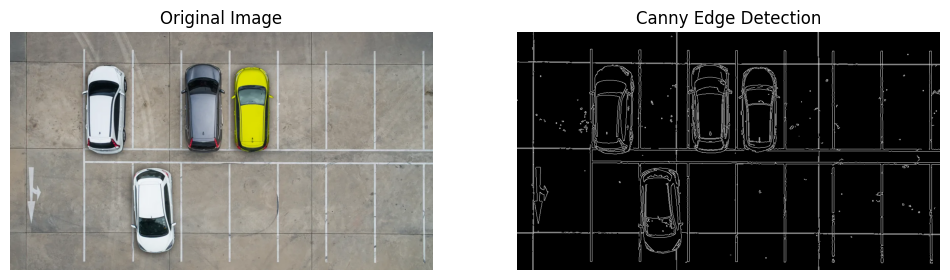

In [ ]:
## 4b. Canny Edge Detection

img = cv.imread('/content/drive/MyDrive/PCVK/Images/Object Detection/Object Detection/Object Detection/car-park.jpg')
gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)

canny = cv.Canny(gray, 100, 200)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(cv.cvtColor(img, cv.COLOR_BGR2RGB))
plt.title('Original Image')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(canny, cmap='gray')
plt.title('Canny Edge Detection')
plt.axis('off')

plt.show()

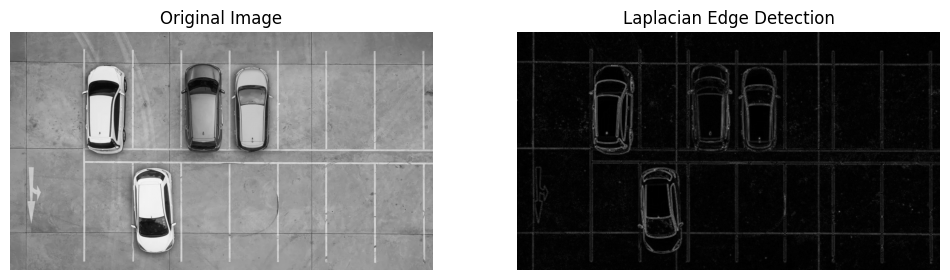

In [ ]:
## 4c. Laplacian Edge Detection

img = cv.imread('/content/drive/MyDrive/PCVK/Images/Object Detection/Object Detection/Object Detection/car-park.jpg')
gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)

blur = cv.GaussianBlur(gray, (3, 3), 0)
laplacian = cv.Laplacian(blur, cv.CV_64F)
laplacian = cv.convertScaleAbs(laplacian)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(gray, cmap='gray')
plt.title('Original Image')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(laplacian, cmap='gray')
plt.title('Laplacian Edge Detection')
plt.axis('off')

plt.show()

5. Implementasi Corner Detection

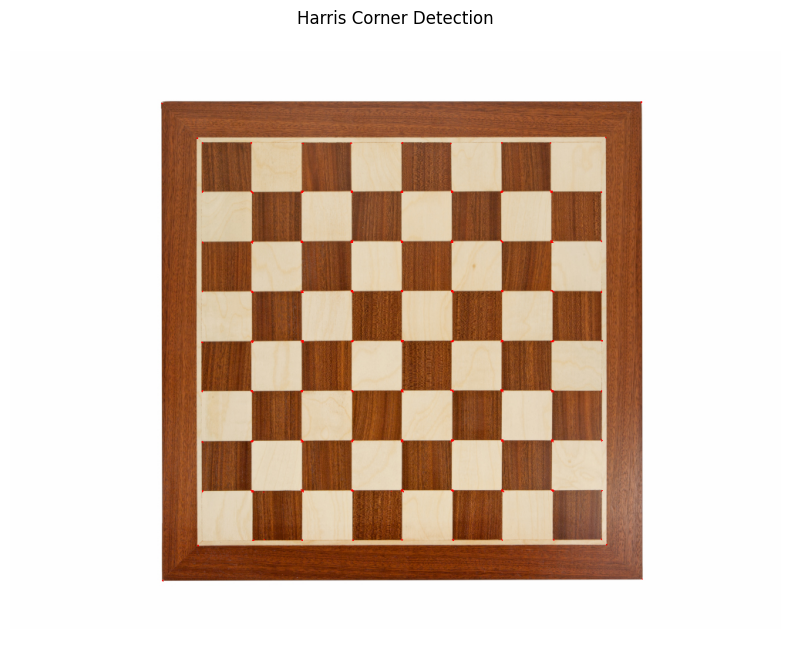

In [ ]:
## 5a. Harris Corner Detection

img = cv.imread('/content/drive/MyDrive/PCVK/Images/Object Detection/Object Detection/Object Detection/chess-board.jpg')
gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)

gray = np.float32(gray)
dst = cv.cornerHarris(gray, 2, 3, 0.04)

img[dst > 0.01 * dst.max()] = [0, 0, 255]

plt.figure(figsize=(10, 8))
plt.imshow(cv.cvtColor(img, cv.COLOR_BGR2RGB))
plt.title('Harris Corner Detection')
plt.axis('off')
plt.show()

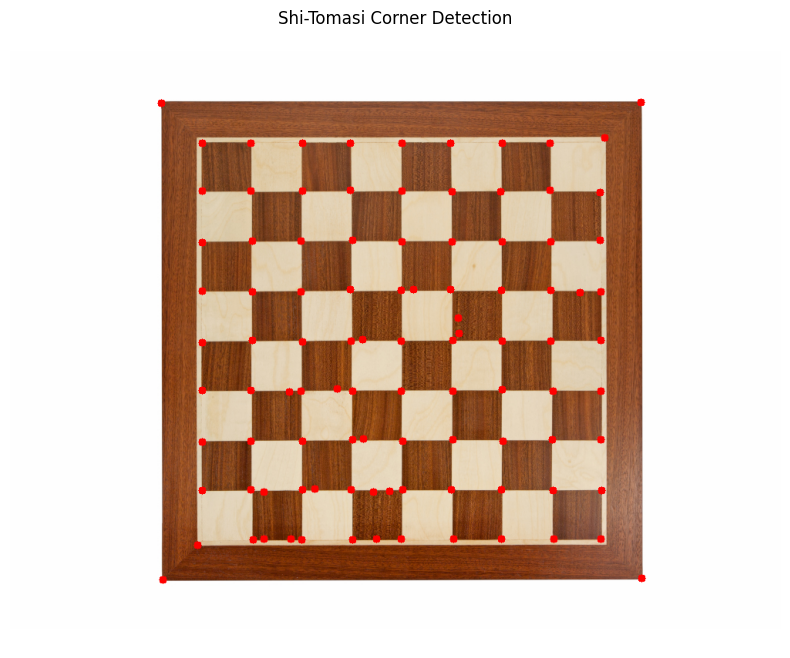

Jumlah sudut terdeteksi: 100


In [ ]:
## 5b. Shi-Tomasi Detection

img = cv.imread('/content/drive/MyDrive/PCVK/Images/Object Detection/Object Detection/Object Detection/chess-board.jpg')
gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)

corners = cv.goodFeaturesToTrack(
    gray,
    maxCorners=100,
    qualityLevel=0.01,
    minDistance=10
)

corners = np.int32(corners)

for corner in corners:
    x, y = corner.ravel()
    cv.circle(img, (x, y), 5, (0, 0, 255), -1)

plt.figure(figsize=(10, 8))
plt.imshow(cv.cvtColor(img, cv.COLOR_BGR2RGB))
plt.title('Shi-Tomasi Corner Detection')
plt.axis('off')
plt.show()

print('Jumlah sudut terdeteksi:', len(corners))

6. Implementasi Hough Transform (Grid Detection)

Berhasil menggambar 18 garis grid unik dan rapi!


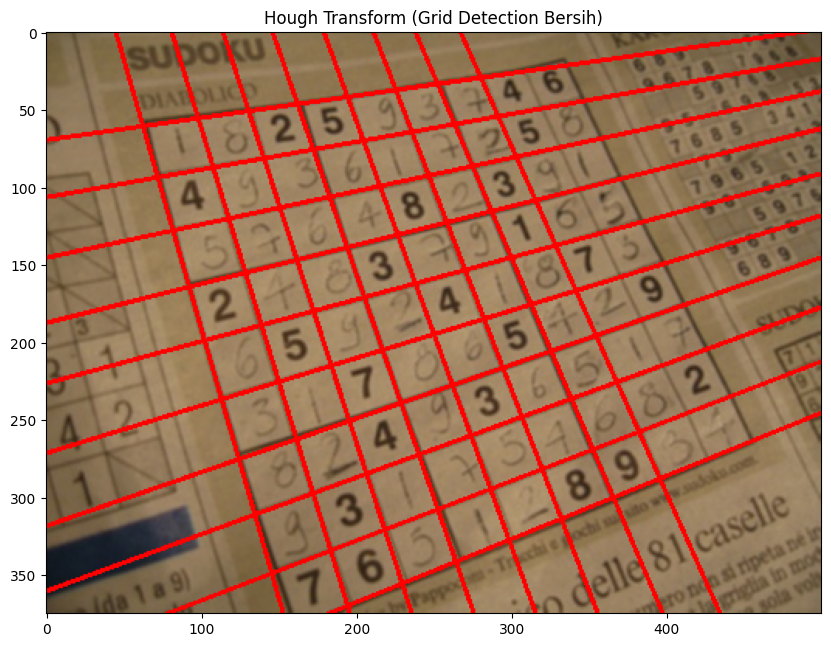

In [58]:
import cv2 as cv
import numpy as np
from matplotlib import pyplot as plt

# 1. Baca gambar
img = cv.imread('/content/drive/MyDrive/PCVK/Images/Object Detection/sudoku.jpg')
gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)

# 2. Canny Edge Detection
edges = cv.Canny(gray, 50, 150, apertureSize=3)

# 3. Dilasi dan Erosi
kernel = np.ones((3,3), np.uint8)
dilated = cv.dilate(edges, kernel, iterations=1)
eroded = cv.erode(dilated, kernel, iterations=1)

# 4. Implementasi HoughLines
lines = cv.HoughLines(eroded, 1, np.pi/180, 275)

# 5. Menggabungkan garis yang mirip & Menggambar
img_hough = img.copy()

if lines is not None:
    # Buat list kosong untuk menyimpan garis yang sudah valid (unik)
    garis_unik = []

    for line in lines:
        rho, theta = line[0]
        theta_deg = theta * (180 / np.pi)

        # FILTER 1: Buang garis miring
        if (theta_deg < 25 or theta_deg > 155) or (65 < theta_deg < 115):

            # FILTER 2: Cek apakah garis ini tumpang tindih dengan garis sebelumnya
            is_double = False
            for (v_rho, v_theta) in garis_unik:
                # Jika selisih jarak (rho) < 20 piksel dan sudut (theta) sangat mirip
                if abs(rho - v_rho) < 20 and abs(theta - v_theta) < 0.1:
                    is_double = True
                    break

            # Jika garis belum ada di posisi tersebut (bukan double), maka gambar
            if not is_double:
                garis_unik.append((rho, theta)) # Simpan ke memori

                a = np.cos(theta)
                b = np.sin(theta)
                x0 = a * rho
                y0 = b * rho

                x1 = int(x0 + 1000 * (-b))
                y1 = int(y0 + 1000 * (a))
                x2 = int(x0 - 1000 * (-b))
                y2 = int(y0 - 1000 * (a))

                cv.line(img_hough, (x1, y1), (x2, y2), (0, 0, 255), 2)

    print(f"Berhasil menggambar {len(garis_unik)} garis grid unik dan rapi!")

# Menampilkan hasil
plt.figure(figsize=(10,10))
plt.imshow(cv.cvtColor(img_hough, cv.COLOR_BGR2RGB))
plt.title('Hough Transform (Grid Detection Bersih)')
plt.axis('on')
plt.show()

7. Implementasi Contour Detection

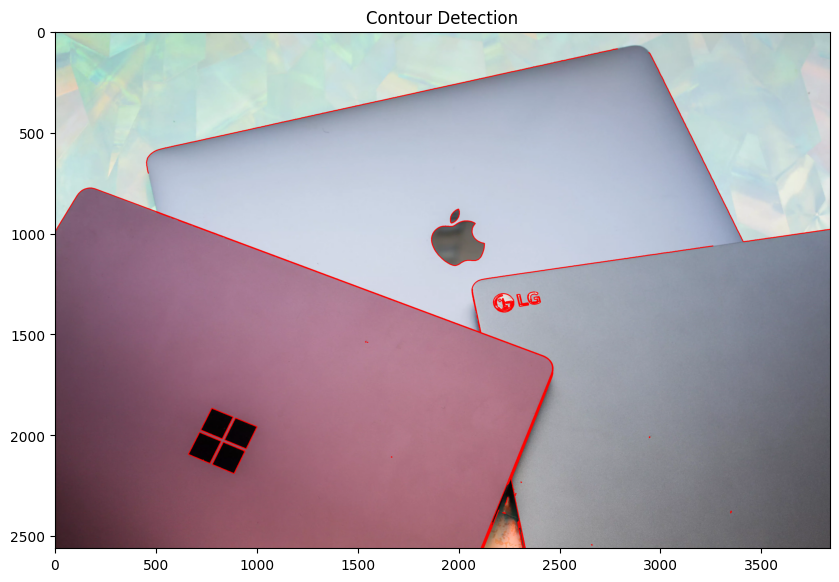

In [47]:
# 1. Baca gambar dan ubah ke Grayscale
img = cv.imread('/content/drive/MyDrive/PCVK/Images/Object Detection/laptop.jpg')
gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)

# 2. Ubah citra menjadi citra biner (Canny edge detection)
# Gunakan variabel 'gray' yang sudah dibuat di atas
edges_laptop = cv.Canny(gray, 100, 200)

# 3. Menemukan kontur
contours, hierarchy = cv.findContours(edges_laptop, cv.RETR_TREE, cv.CHAIN_APPROX_SIMPLE)

# 4. Menggambarkan kontur pada citra asli
# Gunakan variabel 'img' yang sudah dibuat di awal
img_contour = img.copy()
cv.drawContours(img_contour, contours, -1, (0, 0, 255), 3)

# 5. Menampilkan hasil
plt.figure(figsize=(10,10))
plt.imshow(cv.cvtColor(img_contour, cv.COLOR_BGR2RGB))
plt.title('Contour Detection')
plt.axis('on')
plt.show()